<a href="https://colab.research.google.com/github/CGUILLEN23/ADS-504-EV-Adoption-Project/blob/main/ADS_504_Final_Project_EV_Transition_EDA_and_Preprocessing_LR_DT_RF_KNN_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Exploratory Data Analysis and Preprocessing

This section loads the dataset, profiles its structure, identifies and resolves data quality issues (missing values, invalid entries, outliers), explores relationships between features and the target variable, and prepares the data for modeling (encoding, scaling, train/test split). Our target variable, `ev_adoption_likelihood`, is an ordinal categorical variable with three classes: Low, Medium, and High.

In [1]:
import pandas as pd

In [2]:
from google.colab import files

uploaded = files.upload()

Saving global_ev_adoption_behavior_2026.csv to global_ev_adoption_behavior_2026.csv


In [3]:
df = pd.read_csv("global_ev_adoption_behavior_2026.csv")

### Initial Data Profiling

We start by confirming the dataset's structure and size (50,000 rows, 23 columns), reviewing column data types, and checking for any immediate structural issues before diving into data quality.

In [4]:
df.head()

,age,annual_income,education_level,city_type,daily_commute_km,weekly_travel_distance_km,current_vehicle_type,vehicle_age_years,fuel_expense_per_month,charging_station_accessibility,...,environmental_awareness_score,government_incentive_awareness,technology_affinity_score,range_anxiety_score,battery_replacement_concern,ev_knowledge_score,previous_ev_experience,ev_adoption_likelihood,monthly_energy_consumption_kwh,monthly_charging_cost
0,56,23019.0,High School,Suburban,39.8,205.7,Hatchback,6.1,317.1,3.9,...,8.3,6.4,5.2,4.6,3.5,6.9,0,High,199.8,28.5
1,46,26440.0,High School,Suburban,34.6,218.4,Sedan,4.4,290.0,4.5,...,7.8,10.0,5.7,5.5,7.4,6.9,1,High,139.8,22.9
2,46,57167.0,PhD,Suburban,30.5,177.7,Sedan,0.4,201.4,6.3,...,7.6,6.4,7.8,5.3,6.2,6.8,0,High,158.0,38.5
3,23,15841.0,Master,Suburban,44.6,325.9,SUV,0.0,407.3,5.2,...,6.2,5.6,5.1,7.9,5.7,7.2,0,Low,207.0,45.0
4,50,51571.0,Master,Urban,52.4,281.0,SUV,5.2,458.4,4.3,...,9.7,9.9,8.2,2.6,4.7,8.1,0,High,195.6,43.9


In [5]:
df.shape

(50000, 23)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             50000 non-null  int64  
 1   annual_income                   50000 non-null  float64
 2   education_level                 49500 non-null  object 
 3   city_type                       50000 non-null  object 
 4   daily_commute_km                50000 non-null  float64
 5   weekly_travel_distance_km       50000 non-null  float64
 6   current_vehicle_type            50000 non-null  object 
 7   vehicle_age_years               50000 non-null  float64
 8   fuel_expense_per_month          50000 non-null  float64
 9   charging_station_accessibility  49500 non-null  float64
 10  nearest_charging_station_km     50000 non-null  float64
 11  home_charging_available         50000 non-null  int64  
 12  electricity_cost_per_kwh        

In [7]:
df.dtypes

,0
age,int64
annual_income,float64
education_level,object
city_type,object
daily_commute_km,float64
weekly_travel_distance_km,float64
current_vehicle_type,object
vehicle_age_years,float64
fuel_expense_per_month,float64
charging_station_accessibility,float64


### Missing Value Check

Three columns have missing values: `education_level`, `charging_station_accessibility`, and `ev_knowledge_score`, each at ~1% (500 rows). Given the low proportion, we address these later with simple imputation rather than dropping rows, to avoid unnecessary data loss.

In [8]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
education_level,500,1.0
charging_station_accessibility,500,1.0
ev_knowledge_score,500,1.0


### Duplicate Check

No duplicate rows were found, so no deduplication is needed.

In [9]:
df.duplicated().sum()

np.int64(0)

### Target Variable Distribution

The target class is imbalanced: ~59% High, ~24% Medium, ~17% Low. We account for this later by stratifying the train/test split so both sets preserve these proportions.

`df.describe()` also surfaces a red flag: `fuel_expense_per_month` has a minimum of -99.70, which is not physically possible and needs correction.

In [10]:
df["ev_adoption_likelihood"].value_counts()

,count
ev_adoption_likelihood,
High,29670
Medium,12078
Low,8252


In [11]:
df["ev_adoption_likelihood"].value_counts(normalize=True) * 100

,proportion
ev_adoption_likelihood,
High,59.340
Medium,24.156
Low,16.504


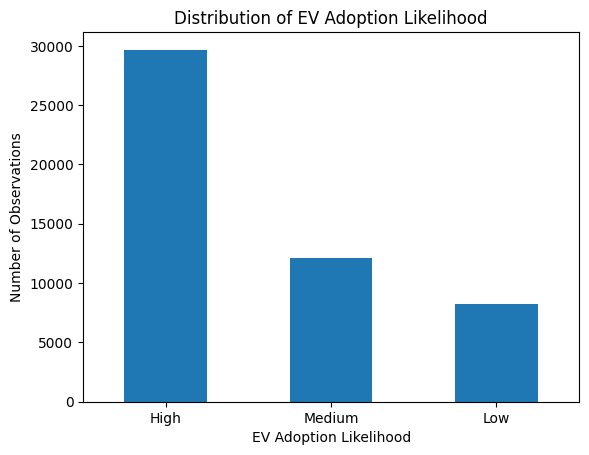

In [12]:
import matplotlib.pyplot as plt

df["ev_adoption_likelihood"].value_counts().plot(kind="bar")

plt.title("Distribution of EV Adoption Likelihood")
plt.xlabel("EV Adoption Likelihood")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,50000.0,44.996080,14.110844,21.00,33.00,45.00,57.00,69.00
annual_income,50000.0,44311.869380,26109.170784,5104.00,25617.75,37891.00,56051.25,250000.00
daily_commute_km,50000.0,35.169358,14.736042,5.00,25.00,35.10,45.20,97.90
weekly_travel_distance_km,50000.0,228.727200,101.147254,25.00,157.70,224.10,294.50,732.30
vehicle_age_years,50000.0,6.012842,2.947132,0.00,3.90,6.00,8.00,20.00
fuel_expense_per_month,50000.0,295.169608,130.178552,-99.70,205.20,294.80,383.00,862.00
charging_station_accessibility,49500.0,5.892947,2.152186,1.00,4.40,5.90,7.40,10.00
nearest_charging_station_km,50000.0,7.132370,4.801992,0.50,3.00,6.90,10.70,28.50
home_charging_available,50000.0,0.649760,0.477050,0.00,0.00,1.00,1.00,1.00
electricity_cost_per_kwh,50000.0,0.215359,0.077914,0.08,0.15,0.22,0.28,0.35


### Data Error Correction and Imputation

**Negative fuel expense:** 271 rows have negative `fuel_expense_per_month` values, which cannot occur in reality. We treat this as a data entry error (likely a sign error) and correct it using absolute value rather than dropping the rows, since the magnitude still appears valid and 271 rows is a small fraction of the data (~0.5%).

**Missing values:** `education_level` is imputed with its mode (most common category), since it's categorical. `charging_station_accessibility` and `ev_knowledge_score` are imputed with their medians, since both are bounded 1–10 score variables where median is more robust to skew than mean.

In [14]:
(df["fuel_expense_per_month"] < 0).sum()

np.int64(271)

In [15]:
df[df["fuel_expense_per_month"] < 0][
    ["fuel_expense_per_month", "daily_commute_km", "current_vehicle_type"]
].head(10)

,fuel_expense_per_month,daily_commute_km,current_vehicle_type
18,-0.7,5.0,Sedan
27,-0.8,7.9,Truck
29,-19.2,5.0,Sedan
137,-11.9,6.0,Sedan
492,-4.5,5.7,Hatchback
688,-22.5,9.7,Sedan
746,-9.2,5.0,SUV
821,-17.5,5.1,Hatchback
874,-20.8,5.0,Sedan
1089,-8.4,5.0,Sedan


In [16]:
# Fix negative fuel_expense_per_month values using absolute values
df["fuel_expense_per_month"] = df["fuel_expense_per_month"].abs()

# verify removal of negative values
print((df["fuel_expense_per_month"] < 0).sum())

# Impute missing values
df["education_level"] = df["education_level"].fillna(df["education_level"].mode()[0])

df["charging_station_accessibility"] = df["charging_station_accessibility"].fillna(
    df["charging_station_accessibility"].median()
)

df["ev_knowledge_score"] = df["ev_knowledge_score"].fillna(
    df["ev_knowledge_score"].median()
)

# verify no missing values remain
print(df.isnull().sum().sum())

0
0


### Outlier Detection

Using the IQR method (1.5×IQR beyond Q1/Q3) across the remaining numeric columns, outlier rates range from 0% (`age`, `electricity_cost_per_kwh`) up to ~3.8% (`annual_income`). All flagged outliers are right-tail only (no implausible lower-bound values), consistent with natural right-skew in variables like income and travel distance rather than data errors. We retain these values rather than removing or capping them, since they represent plausible real-world cases. We note `annual_income` and `monthly_charging_cost` as candidates for log-transformation if a linear/distance-based model proves sensitive to their skew.

In [17]:
import numpy as np

# Numeric columns to check for outliers
cols_to_check = [
    "age", "annual_income", "daily_commute_km", "weekly_travel_distance_km",
    "vehicle_age_years", "fuel_expense_per_month", "nearest_charging_station_km",
    "electricity_cost_per_kwh", "monthly_energy_consumption_kwh", "monthly_charging_cost"
]

# IQR method - flag values outside 1.5*IQR from Q1/Q3
outlier_summary = {}

for col in cols_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_summary[col] = len(outliers)

outlier_df = pd.DataFrame.from_dict(outlier_summary, orient="index", columns=["outlier_count"])
outlier_df["outlier_pct"] = (outlier_df["outlier_count"] / len(df)) * 100
print(outlier_df.sort_values("outlier_pct", ascending=False))

                                outlier_count  outlier_pct
annual_income                            1882        3.764
monthly_charging_cost                    1124        2.248
monthly_energy_consumption_kwh            646        1.292
weekly_travel_distance_km                 377        0.754
daily_commute_km                          192        0.384
fuel_expense_per_month                    173        0.346
vehicle_age_years                         170        0.340
nearest_charging_station_km                42        0.084
age                                         0        0.000
electricity_cost_per_kwh                    0        0.000


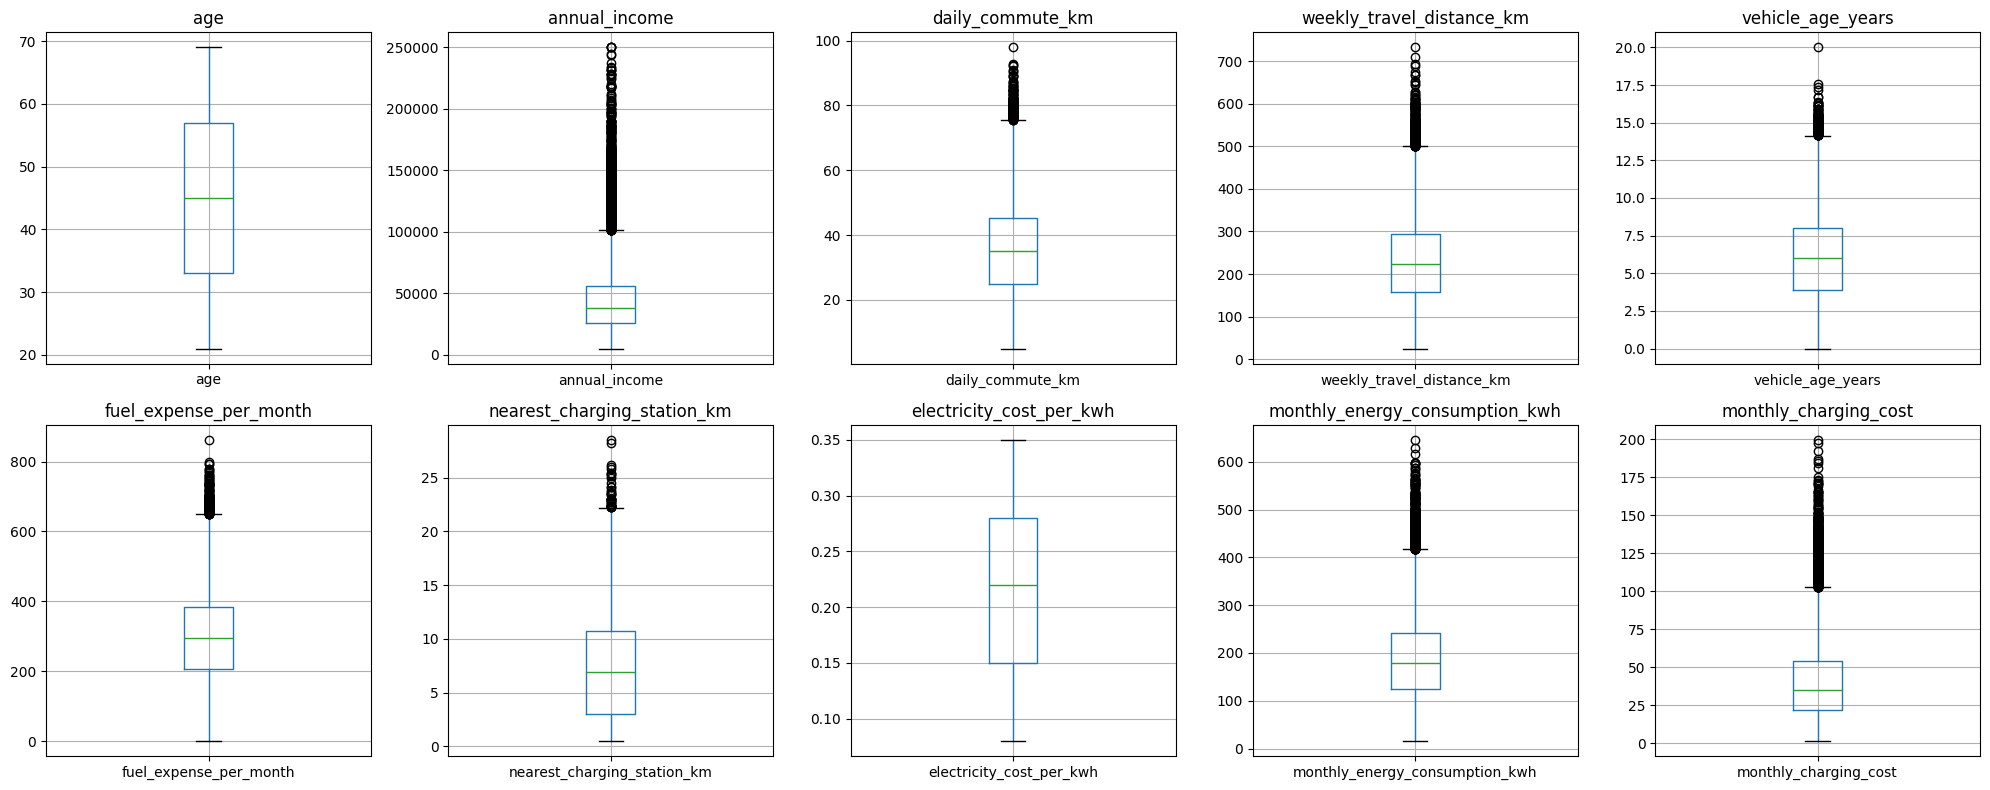

In [18]:
# Boxplots
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, col in enumerate(cols_to_check):
    df.boxplot(column=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

### Correlation Analysis

A correlation heatmap across numeric features reveals a multicollinear cluster: `daily_commute_km`, `weekly_travel_distance_km`, `fuel_expense_per_month`, `monthly_energy_consumption_kwh`, and `monthly_charging_cost` are all correlated at 0.7–0.95, which makes intuitive sense (more driving drives up fuel/energy/charging costs together). We address this below by dropping two redundant columns.

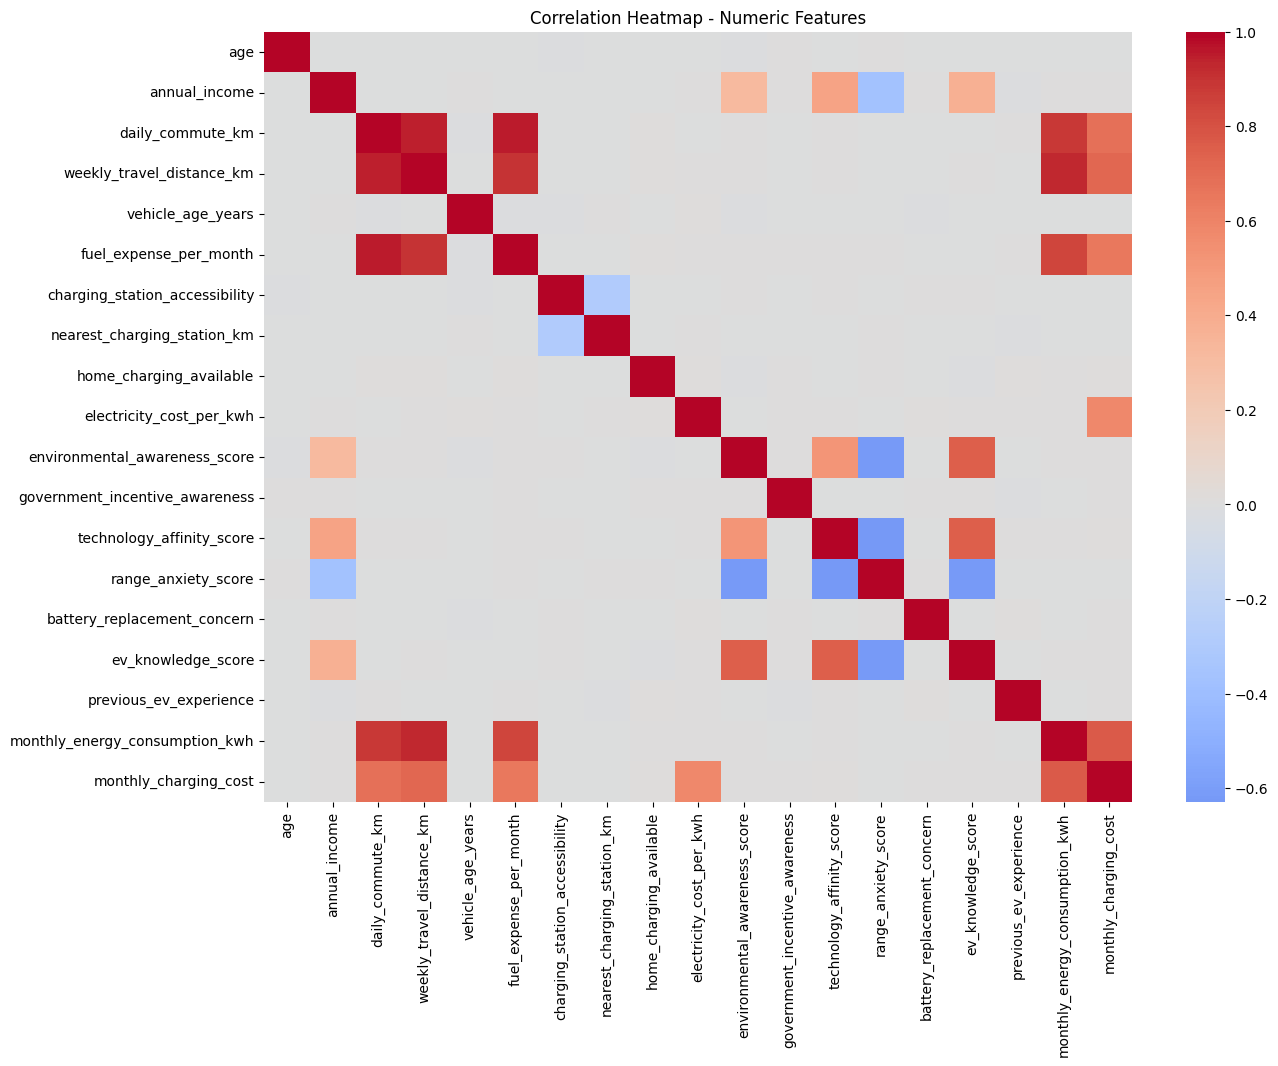

daily_commute_km                fuel_expense_per_month            0.951789
weekly_travel_distance_km       daily_commute_km                  0.944852
monthly_energy_consumption_kwh  weekly_travel_distance_km         0.936115
weekly_travel_distance_km       fuel_expense_per_month            0.899121
monthly_energy_consumption_kwh  daily_commute_km                  0.884948
fuel_expense_per_month          monthly_energy_consumption_kwh    0.842395
monthly_energy_consumption_kwh  monthly_charging_cost             0.765091
ev_knowledge_score              technology_affinity_score         0.752686
environmental_awareness_score   ev_knowledge_score                0.748801
monthly_charging_cost           weekly_travel_distance_km         0.715476
dtype: float64


In [19]:
# Correlation heatmap (numeric features only)
import seaborn as sns

numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap - Numeric Features")
plt.show()

# Top 10 Correlated features
corr_pairs = corr.abs().unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1].drop_duplicates()
print(corr_pairs.head(10))

### Feature Relationships with Target

Grouping key features by adoption class shows clean separation for `environmental_awareness_score`, `technology_affinity_score`, and `range_anxiety_score` — High-adoption respondents show higher awareness/tech affinity and lower range anxiety than Low-adoption respondents. These are expected to be strong predictors for modeling.

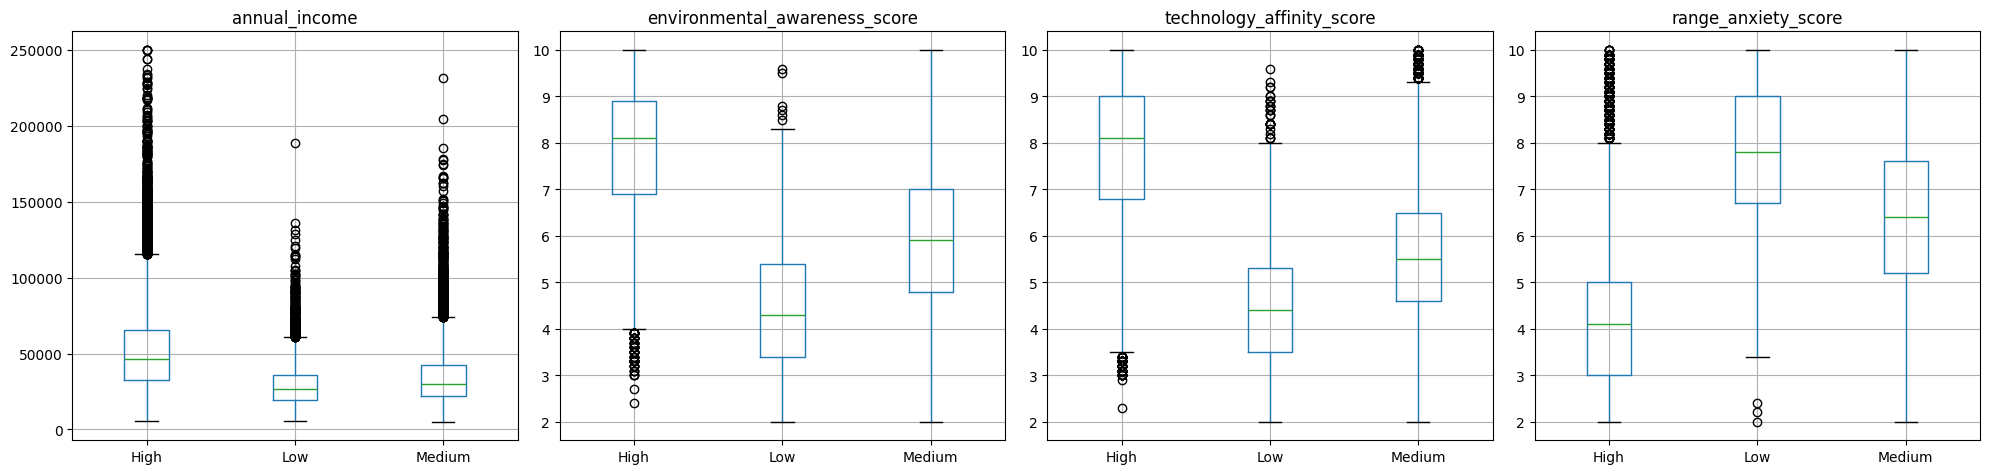

In [20]:
# Boxplots of a few key features grouped by target class
features_to_compare = ["annual_income", "environmental_awareness_score",
                        "technology_affinity_score", "range_anxiety_score"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, col in enumerate(features_to_compare):
    df.boxplot(column=col, by="ev_adoption_likelihood", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")

plt.suptitle("")
plt.tight_layout()
plt.show()

### Feature Selection: Resolving Multicollinearity

To reduce redundancy identified in the correlation analysis, we drop `daily_commute_km` (redundant with `weekly_travel_distance_km`, which captures the same usage pattern at a less noisy weekly granularity) and `monthly_energy_consumption_kwh` (redundant with `monthly_charging_cost`, the more directly interpretable variable). This reduces multicollinearity for linear models without losing meaningful insight.

In [21]:
# Drop redundant/multicollinear columns
df = df.drop(columns=["daily_commute_km", "monthly_energy_consumption_kwh"])


print(df.shape)

(50000, 21)


### Encoding

The target variable is ordinal (Low < Medium < High), so it's mapped to integers 0/1/2 rather than one-hot encoded, preserving its inherent order. The three nominal categorical features (`education_level`, `city_type`, `current_vehicle_type`) are one-hot encoded with `drop_first=True` to avoid the dummy variable trap.

In [22]:
# Encode target (ordinal - Low < Medium < High)
adoption_map = {"Low": 0, "Medium": 1, "High": 2}
df["ev_adoption_likelihood"] = df["ev_adoption_likelihood"].map(adoption_map)

# One-hot encode nominal categoricals
df = pd.get_dummies(df, columns=["education_level", "city_type", "current_vehicle_type"], drop_first=True)

print(df.shape)
df.head()

(50000, 26)


,age,annual_income,weekly_travel_distance_km,vehicle_age_years,fuel_expense_per_month,charging_station_accessibility,nearest_charging_station_km,home_charging_available,electricity_cost_per_kwh,environmental_awareness_score,...,ev_adoption_likelihood,monthly_charging_cost,education_level_High School,education_level_Master,education_level_PhD,city_type_Suburban,city_type_Urban,current_vehicle_type_SUV,current_vehicle_type_Sedan,current_vehicle_type_Truck
0,56,23019.0,205.7,6.1,317.1,3.9,9.5,1,0.14,8.3,...,2,28.5,True,False,False,True,False,False,False,False
1,46,26440.0,218.4,4.4,290.0,4.5,11.6,1,0.16,7.8,...,2,22.9,True,False,False,True,False,False,True,False
2,46,57167.0,177.7,0.4,201.4,6.3,6.4,1,0.24,7.6,...,2,38.5,False,False,True,True,False,False,True,False
3,23,15841.0,325.9,0.0,407.3,5.2,8.8,0,0.22,6.2,...,0,45.0,False,True,False,True,False,True,False,False
4,50,51571.0,281.0,5.2,458.4,4.3,0.5,0,0.22,9.7,...,2,43.9,False,True,False,False,True,True,False,False


### Train/Test Split and Feature Scaling

We split the data 80/20 with stratification on the target to preserve class proportions, given the class imbalance noted earlier. Numeric features are then standardized using `StandardScaler`, fit only on the training set and applied to the test set via transform, to prevent data leakage. Scaling is primarily needed for logistic regression; the tree-based models (decision tree, random forest) are scale-invariant, but the scaled features can be used consistently across all three without affecting tree-based model performance.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop(columns=["ev_adoption_likelihood"])
y = df["ev_adoption_likelihood"]

# Train/test split - stratify to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(40000, 25) (10000, 25)
ev_adoption_likelihood
2    0.59340
1    0.24155
0    0.16505
Name: proportion, dtype: float64
ev_adoption_likelihood
2    0.5934
1    0.2416
0    0.1650
Name: proportion, dtype: float64


In [24]:
# Scale numeric features
numeric_cols = ["age", "annual_income", "weekly_travel_distance_km", "vehicle_age_years",
                 "fuel_expense_per_month", "charging_station_accessibility",
                 "nearest_charging_station_km", "electricity_cost_per_kwh",
                 "environmental_awareness_score", "government_incentive_awareness",
                 "technology_affinity_score", "range_anxiety_score",
                 "battery_replacement_concern", "ev_knowledge_score",
                 "monthly_charging_cost"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])  # transform only, no fit yet

X_train_scaled.head()

,age,annual_income,weekly_travel_distance_km,vehicle_age_years,fuel_expense_per_month,charging_station_accessibility,nearest_charging_station_km,home_charging_available,electricity_cost_per_kwh,environmental_awareness_score,...,previous_ev_experience,monthly_charging_cost,education_level_High School,education_level_Master,education_level_PhD,city_type_Suburban,city_type_Urban,current_vehicle_type_SUV,current_vehicle_type_Sedan,current_vehicle_type_Truck
35331,-0.353010,-0.518434,1.973057,-0.854466,1.364782,0.560764,-0.026666,0,0.699900,-0.377411,...,1,3.043811,False,True,False,False,True,False,False,False
16410,-0.353010,-0.166229,-0.430327,0.807253,0.260204,-0.748593,1.307461,0,-1.353599,-0.585953,...,0,-1.062042,False,False,False,False,False,False,False,False
21603,-0.140227,0.392094,0.276260,1.044642,0.735797,0.794577,0.390248,1,-0.198506,-0.950902,...,1,0.422628,False,False,False,False,False,False,False,True
25075,-1.345995,-0.164425,0.629060,-1.397069,1.340116,0.747815,-0.568656,1,-0.455193,-0.533818,...,0,-0.161635,True,False,False,True,False,False,True,False
11746,1.703888,-1.010776,0.017343,-0.074476,0.402805,-0.468017,-0.151741,0,0.699900,-0.846631,...,0,0.462646,False,False,False,False,False,False,True,False


### Applying Models
In this stage, supervised machine learning algorithms are trained and tested to predict whether a consumer is likely to purchase an electric vehicle based on demographic, financial and behavioral features. The pre-processed training data is used for Logistic Regression, Decision Tree, K-nearest neighbors and Random Forest and their performance is compared using metrics like accuracy, precision, recall, F1-score and confusion matrices to identify the best performing model for this prediction task.

#### Logistic Regression

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train Logistic Regression
log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

log_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_log = log_model.predict(X_test_scaled)

# Evaluation
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_log),4))

print("\nClassification Report")
print(classification_report(y_test, y_pred_log))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_log))

Logistic Regression Accuracy: 0.8793

Classification Report
              precision    recall  f1-score   support

           0       0.87      0.82      0.85      1650
           1       0.75      0.75      0.75      2416
           2       0.94      0.95      0.94      5934

    accuracy                           0.88     10000
   macro avg       0.85      0.84      0.85     10000
weighted avg       0.88      0.88      0.88     10000


Confusion Matrix
[[1361  289    0]
 [ 208 1823  385]
 [   0  325 5609]]


#### Decision Tree

In [26]:
from sklearn.tree import DecisionTreeClassifier

# Train Decision Tree
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=6
)

tree_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_tree = tree_model.predict(X_test_scaled)

# Evaluation
print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred_tree),4))

print("\nClassification Report")
print(classification_report(y_test, y_pred_tree))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_tree))

Decision Tree Accuracy: 0.7872

Classification Report
              precision    recall  f1-score   support

           0       0.75      0.60      0.67      1650
           1       0.57      0.61      0.59      2416
           2       0.89      0.91      0.90      5934

    accuracy                           0.79     10000
   macro avg       0.73      0.71      0.72     10000
weighted avg       0.79      0.79      0.79     10000


Confusion Matrix
[[ 995  622   33]
 [ 314 1476  626]
 [  21  512 5401]]


#### Random Forest

In [27]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)

# Evaluation
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf),4))

print("\nClassification Report")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.8501

Classification Report
              precision    recall  f1-score   support

           0       0.84      0.77      0.80      1650
           1       0.69      0.69      0.69      2416
           2       0.92      0.94      0.93      5934

    accuracy                           0.85     10000
   macro avg       0.82      0.80      0.81     10000
weighted avg       0.85      0.85      0.85     10000


Confusion Matrix
[[1271  378    1]
 [ 243 1666  507]
 [   1  369 5564]]


#### K-Nearest Neighbors (KNN)

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

k_values = [3, 5, 7, 9, 11, 15, 20, 25]
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(
        knn,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='accuracy'
    )
    cv_scores.append(scores.mean())

for k, score in zip(k_values, cv_scores):
    print(f"k={k}: CV Accuracy = {score:.4f}")

best_k = k_values[cv_scores.index(max(cv_scores))]
print(f"Best k value: {best_k}")

k=3: CV Accuracy = 0.7920
k=5: CV Accuracy = 0.8095
k=7: CV Accuracy = 0.8187
k=9: CV Accuracy = 0.8240
k=11: CV Accuracy = 0.8270
k=15: CV Accuracy = 0.8306
k=20: CV Accuracy = 0.8343
k=25: CV Accuracy = 0.8369
Best k value: 25


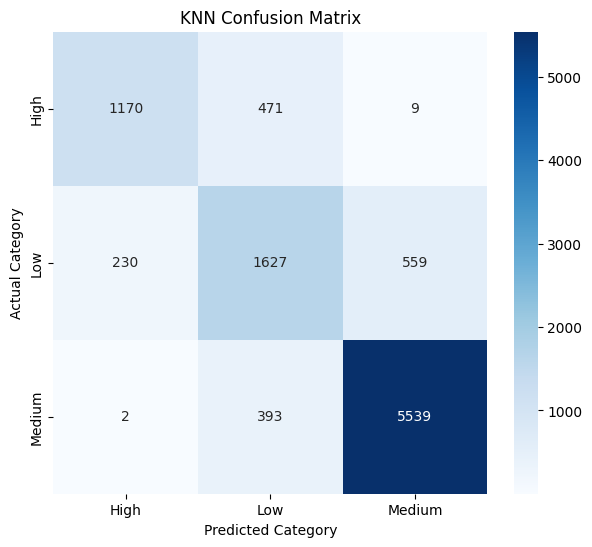

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix array
cm = confusion_matrix(y_test, y_pred_knn)

# Define the class labels based on the presumed encoding (0: High, 1: Low, 2: Medium)
class_labels = ['High', 'Low', 'Medium']

# Plot using Seaborn's heatmap
plt.figure(figsize=(7, 6)) # Adjusted figure size for better readability
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)

plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.title('KNN Confusion Matrix')
plt.show()

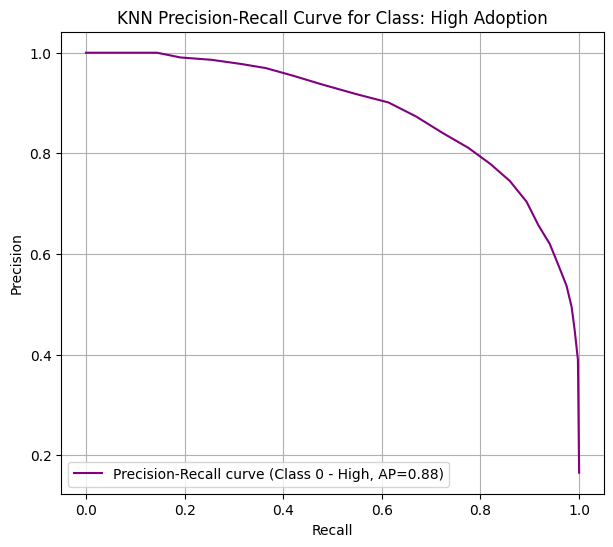

In [36]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Get probability estimates for all classes
y_proba = knn_model.predict_proba(X_test_scaled)

# For multi-class, plot one Precision-Recall curve per class (e.g., for 'High' adoption, which is class 0)
# Binarize the true labels for class 0
y_test_binarized_class_0 = (y_test == 0).astype(int)

# Get the probability estimates for class 0
y_probs_class_0 = y_proba[:, 0]

# Calculate precision and recall for class 0
precision_class_0, recall_class_0, _ = precision_recall_curve(y_test_binarized_class_0, y_probs_class_0)

# Calculate Average Precision Score for class 0
avg_precision_class_0 = average_precision_score(y_test_binarized_class_0, y_probs_class_0)

plt.figure(figsize=(7, 6))
plt.plot(recall_class_0, precision_class_0, color='purple', label=f'Precision-Recall curve (Class 0 - High, AP={avg_precision_class_0:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('KNN Precision-Recall Curve for Class: High Adoption')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

# You can extend this to plot for other classes (1 and 2) similarly

In [29]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_knn):.4f}")
print(classification_report(y_test, y_pred_knn))

Test Accuracy: 0.8336
              precision    recall  f1-score   support

           0       0.83      0.71      0.77      1650
           1       0.65      0.67      0.66      2416
           2       0.91      0.93      0.92      5934

    accuracy                           0.83     10000
   macro avg       0.80      0.77      0.78     10000
weighted avg       0.83      0.83      0.83     10000



#### Model Comparison

In [32]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_knn)
    ]
})

results = (
    results
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)

results

,Model,Accuracy
0,Logistic Regression,0.8793
1,Random Forest,0.8501
2,KNN,0.8336
3,Decision Tree,0.7872


**Observations:**
Of the four models, Logistic Regression performed best with an accuracy of 87.93%, followed by Random Forest at 85.01%, KNN at 83.36%, and Decision Tree at 78.72%. Logistic Regression provided the strongest overall performance while also remaining simple and interpretable. Random Forest was able to capture more complex relationships, but the added complexity did not improve performance over Logistic Regression. KNN also performed well after tuning the value of k using cross-validation, but its final test accuracy remained below Logistic Regression and Random Forest. Decision Tree had the lowest accuracy of the four models.